# Links

GitHub repository:
https://github.com/nylandgit/IND320-Repo

Streamlit app:
https://nylandgit-ind320-repo.streamlit.app/

Code runthrough video:


# AI Statement and Descriptive Log

## AI Statement

This project has used the free VS Code Copilot generative AI to: Generate code, identify bugs, fix bugs, brainstorm technical solutions, and to teach the process of coding through in-depth explanations of each generated line of code. Some Google searches have also involved Google's built-in generative AI.

The project author has steered the AI's coding through accepting, rejecting, and modifying the AI's code based on the author's intuition. The author has requested code explanations, studied the AI's code, and made explanatory comments for each code block based on the author's understanding.

The code provided is therefore created partly by the author and partly by generative AI. The explanatory code comments are written exclusively by the author.

Anthropic's Claude was used to develop the Open-Meteo API data retreival code and the lag-based machine learning forecast_filling() function.

## Descriptive Log

### To-Do For Part 4 (When all comes together! :) )
* Clean up Streamlit app, improve user experience, make dashboard coherent and intuitive.
* Improve quality of plots and graphs. Create explanations where relevant.
* Consider sentralizing the taking of user input in side panel to show their effects across various plots, rather than spread user inputs over multiple pages. Generally break free of the task text design and create something better.
* Optimize Streamlit pages' resource usage, make the app run faster and smoother with reduced wait times.
* Clean up GitHub repository. Remove unneeded and mistakenly tracked files. Add ReadMe and explanation of file structure.
* Create updated requirements.txt, or alternatively uv.lock.
* Finalize Streamlit app and GitHub repo so they are presentable, usable, and as good as they can be.

<p></p>
<p></p>

### Section 1:
* Created Norges Bank API retrieval function currency_download(), used custom url from Norges Bank website based on relevant data filters. Tested function.
* Investigated timezone differences across API data. See section 1.2 for conclusions.

<p></p>
<p></p>

### Section 2:
* Spent a very, very long time learning the ins and outs of lag-based machine learning.
* Developed demo lag-based machine learning forecast_function().
* Developed demo test code to test forecast_function().
* Tested forecast_function(). Results are shown in a table and plotted such that they are easy to interpret. The goal is to find the best possible prediction model and parameters combination and set this one as these as defaults in Streamlit, allowing the user to change parts where relevant.
* Completed initial testing, no surprise certain parameter combinations work better than others. Taking a break from this part of the work to focus on something else.
* Restarted testing. Playing around with sections 2.2 and 2.3.
* Overpowered the AI slop and designed key functional and logical requirements, revised DEF and TEST code cells (2.2 and 2.3 respectively) such that Streamlit page content can be finished.
* Done further testing, began report. Postponing final round of testing until all other tasks are finished. Will use function with placeholder defaults = best parameter combinations from initial testing.
* Finalised testing. Defined Streamlit option ranges and defaults. See 2.4 for report.

<p></p>
<p></p>

### Section 3:
* Created Streamlit page layout demo in MS Paint, the software of choice in matters of art and beauty.

<p></p>
<p></p>

### Streamlit
* Updated plots for SATV and LOF to use Plotly for drawing figures.
* Updated SATV and LOF to give the user the choice between temperature and precipitation analysis. Felt somewhat sour to redo work I removed from Part 3 related to the SATV on temperature data, but luckily I also felt somewhat satisfied to have seen this update coming. Ate food, felt exclusively satisfied :)
* Updated SATV and LOF to incorporate a button that restores default analysis parameters.
* Created page layout sketch. Will update after all new functionality is in place.
* Created elevation handling on/off button on meteo data retrieval page, default off as this does increase execution time somewhat.

<p></p>

* Converted shapefiles to geoJSON using online tool found at: https://geoutil.com/converters/shapefile-to-geojson.html
* Developed map demo.
* Encountered issues with precipitation area boundaries. Suspect the problem is rooted in precipitation areas implementation in Part 3, will investigate further at a later stage. Placeholder solution (reusing electricity areas) established temporarily.
* Solved issue with precipitation area boundaries by redesigning radio buttons and their linkages to each .geojson file. The map can now be shown with boundaries for either electricy or weather areas.
* Created placeholder temperature and precipitation drop-down selector. These are not connected to any weather data yet.

<p></p>

* Created forecasting page based on forecast_function() from Section 2.2.
* User input boxes and buttons are a bunch of placeholders. Waiting with finishing until Streamlit page redesign is implemented. Default model(s) option(s) will be incorporated once final testing in Section 2.3 is complete.
* Finalised Forecast page, see 3.2 for report.

<p></p>

* Created Sliding Window Correlation page.
* Found that filling ratio and precipitation correlates suspiciously little (0.1-0.5). Not necessary wrong. Investigating further.

<p></p>

* Initiated refactoring.
* Created page selector inspired by sketch. Mouse-over activation proved difficult, so single-click compromise was made. Selector still works nicely.
* Gone page-by-page squashing bugs and implementing remaining functionality. Genuinely fun process. Creating hundreds of changes to upgrade the app as much as possible.
* Semi-finalised Map page. Still needs to handle VASS and retrieve Weather Area data for plotting.
* Finalised Data Plots page.
* Semi-finalised Forecast page. Still needs model option (if relevant).
* Finalised STL/Spectrogram page.
* Finalised In-Out MW Flows page.
* Finalised Forecast page.


## 1. Norges Bank API, API Timezones

### 1.1 Currency Exchange Rates Function

In [ ]:
import pandas as pd
import requests

# Creating function as instructed.
def currency_download():

    # Defining url copied from NB API website where custom urls can be made.
    url = "https://data.norges-bank.no/api/data/EXR/B.USD+EUR.NOK.SP?endPeriod=2026-11-18&format=sdmx-json&locale=en&startPeriod=1999-01-04"

    # Retrieving data from API with .get().
    response = requests.get(url, timeout=45)
    response.raise_for_status()

    # The API returns requested data according to the SDMX-JSON standard, as
    # indicated by the url. To correctly extract the data to a pandas df, the
    # response needs to be decoded. .json() parses the HTTP response into
    # Python lists and dictionaries.
    nb_response = response.json()

    # Selecting dataset and defining dimensions and dates for soon-to-be df.
    dataset = nb_response["data"]["dataSets"][0]
    dimensions = nb_response["data"]["structure"]["dimensions"]
    dates = dimensions["observation"][0]["values"]

    # Iterating over each currency series in dataset to populate rows with data
    # for soon-to-be df.
    rows = []
    for key, series in dataset["series"].items():
        
        # Mapping data (?).
        indexes = [int(i) for i in key.split(":")]
        labels = {
            dimension["id"]: dimension["values"][i]["id"]
            for dimension, i in zip(dimensions["series"], indexes)
        }

        # Iterating over each observation (data point) in each series.
        for period_index, observation in series["observations"].items():
            
            # Adding data to rows for soon-to-be df.
            rows.append({
                "date": dates[int(period_index)]["id"],
                "currency": labels["BASE_CUR"],
                "rate": float(observation[0]),
            })

    # Creating df based on data in rows.
    df = pd.DataFrame(rows).pivot(
        index="date", columns="currency", values="rate")
    
    df.columns = [f"{currency}_rate" for currency in df.columns]
    df = df.reset_index()[["date", "USD_rate", "EUR_rate"]]

    #print(df)
    return df

df_retrieved = currency_download()
print(df_retrieved)


            date  USD_rate  EUR_rate
0     1999-01-04    7.5112    8.8550
1     1999-01-05    7.4378    8.7745
2     1999-01-06    7.4326    8.7335
3     1999-01-07    7.4142    8.6295
4     1999-01-08    7.3677    8.5900
...          ...       ...       ...
7018  2026-11-12    9.5325   10.5630
7019  2026-11-13    9.5634   10.5695
7020  2026-11-16    9.6005   10.5740
7021  2026-11-17    9.6237   10.5755
7022  2026-11-18    9.6686   10.6045

[7023 rows x 3 columns]


### 1.2 API Timezone Investigation and Conclusion

The task was completed by prompting GitHub copilot to inspect all relevant files calling the APIs and/or data from them. The results have been compiled by the author.

Weekly/daily observations:

* NVE Magasinstatistikk: Weekly observations. Timezone-naive, the retrieved data does not include timezone specifications. Timestamps for observations are treated as dates, Norwegian timezone assumed if relevant.
* Norges Bank: Daily observations, timezone-naive. Timestamps for observations are treated as dates, Norwegian timezone assumed if relevant.

<p></p>

Hourly observations:

* ENTSO-E: Hourly observations. Timezone-aware, called by entsoe-py in Section 3.2 of project_work_part2.ipynb. The time data is converted to UTC+0, which in turn has been placed into Cassandra and MongoDB.
* Open-Meteo: Hourly observations. Timezone-aware, UTC "Europe/Oslo", i.e. UTC+1 for winter time and UTC+2 for summer time.

Conclusion:

ENTSO-E and Open-Meteo use hourly observations, but Open-Meteo is 1 hour ahead of ENTSO-E in winter time and 2 hours ahead in summer time.

NVE Magasinstatistikk and Norges Bank use weekly and daily observations (respectively).

For cross-API comparisons of data points, a UTC conversion may be necessary. The author will investigate which API data must be converted to fit the other(s) on a case-by-case basis. ENTSO-E data has been placed into Cassandra and MongoDB, so it may be preferable to avoid changes to this data. However, as the three other APIs all use Norwegian timezones, it may be beneficial to make only one change to ENTSO-E, rather than three changes to the other APIs.

### 1.3 Sampling of APIs (not necessary, used in investigation)

In [ ]:
# This code is AI-derived, the author has not spent much time on it, hence
# the lack of comments.
import os
from datetime import timedelta

import pandas as pd
import requests
import openmeteo_requests
from retry_requests import retry
from entsoe import EntsoePandasClient

def api_time_sample():
    """Print four observations from each of the four APIs."""

    print("\n=== MAGASINSTATISTIKK ===")
    mag_url = (
        "https://biapi.nve.no/magasinstatistikk/api/"
        "Magasinstatistikk/HentOffentligData"
    )
    mag_response = requests.get(mag_url, timeout=45)
    mag_response.raise_for_status()

    mag = pd.DataFrame(mag_response.json())
    mag = mag.rename(columns={
        "dato_Id": "Date",
        "neste_Publiseringsdato": "Next Publishing Date",
        "omrType": "Area Type",
        "omrnr": "Area Number",
    })
    mag["Date"] = pd.to_datetime(mag["Date"], errors="coerce")

    print(mag[[
        "Date",
        "Area Type",
        "Area Number",
        "fyllingsgrad",
    ]].head(4).to_string(index=False))

    print("\n=== ENTSO-E ===")
    api_key = os.getenv("ENTSO_API_KEY")

    if not api_key:
        print("ENTSO_API_KEY environment variable is not configured.")
    else:
        entsoe_client = EntsoePandasClient(api_key=api_key)
        end = pd.Timestamp.now(tz="UTC").floor("h")
        start = end - timedelta(days=7)

        entsoe_series = entsoe_client.query_crossborder_flows(
            "NO_1",
            "SE_3",
            start=start,
            end=end,
        )

        entsoe = entsoe_series.rename(
            "flow_mw"
        ).rename_axis("timestamp").reset_index()

        entsoe["timestamp"] = pd.to_datetime(
            entsoe["timestamp"],
            utc=True,
        )

        print(entsoe.head(4).to_string(index=False))

    print("\n=== OPEN-METEO ===")
    retry_session = retry(
        requests.Session(),
        retries=5,
        backoff_factor=0.2,
    )
    openmeteo = openmeteo_requests.Client(session=retry_session)

    weather_url = "https://archive-api.open-meteo.com/v1/archive"
    parameters = {
        "latitude": 59.91,
        "longitude": 10.75,
        "start_date": "2024-01-01",
        "end_date": "2024-01-02",
        "hourly": ["temperature_2m", "precipitation"],
        "timezone": "Europe/Oslo",
    }

    responses = openmeteo.weather_api(
        weather_url,
        params=parameters,
    )
    response = responses[0]
    hourly = response.Hourly()

    weather = pd.DataFrame({
        "date": pd.date_range(
            start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
            end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
            freq=pd.Timedelta(seconds=hourly.Interval()),
            inclusive="left",
        ).tz_convert("Europe/Oslo"),
        "temperature_2m": hourly.Variables(0).ValuesAsNumpy(),
        "precipitation": hourly.Variables(1).ValuesAsNumpy(),
    })
    weather["UTC"] = weather["date"].dt.tz_convert("UTC")

    print(weather.head(4).to_string(index=False))

    print("\n=== NORGES BANK ===")
    nb_url = (
        "https://data.norges-bank.no/api/data/"
        "EXR/B.USD+EUR.NOK.SP"
        "?startPeriod=2024-01-01"
        "&endPeriod=2024-01-10"
        "&format=sdmx-json"
        "&locale=en"
    )
    nb_response = requests.get(nb_url, timeout=45)
    nb_response.raise_for_status()

    nb_json = nb_response.json()
    dataset = nb_json["data"]["dataSets"][0]

    dates = (
        nb_json["data"]["structure"]["dimensions"]["observation"][0]
        ["values"]
    )
    series_dimensions = (
        nb_json["data"]["structure"]["dimensions"]["series"]
    )
    currency_values = series_dimensions[1]["values"]

    rows = []
    for key, series in dataset["series"].items():
        currency_index = int(key.split(":")[1])
        currency = currency_values[currency_index]["id"]

        for position, observation in series["observations"].items():
            rows.append({
                "date": dates[int(position)]["id"],
                "currency": currency,
                "rate": float(observation[0]),
            })

    nb = pd.DataFrame(rows).pivot(
        index="date",
        columns="currency",
        values="rate",
    ).reset_index()

    print(nb.head(4).to_string(index=False))

api_time_sample()



=== MAGASINSTATISTIKK ===
      Date Area Type  Area Number  fyllingsgrad
2020-11-15        EL            1      0.974361
2011-08-28        EL            4      0.786499
1998-07-05        EL            3      0.793969
2011-03-27        EL            4      0.300820

=== ENTSO-E ===
ENTSO_API_KEY environment variable is not configured.

=== OPEN-METEO ===
                     date  temperature_2m  precipitation                       UTC
2024-01-01 00:00:00+01:00         -4.0805            0.2 2023-12-31 23:00:00+00:00
2024-01-01 01:00:00+01:00         -3.9805            0.1 2024-01-01 00:00:00+00:00
2024-01-01 02:00:00+01:00         -3.7305            0.9 2024-01-01 01:00:00+00:00
2024-01-01 03:00:00+01:00         -4.0305            0.6 2024-01-01 02:00:00+00:00

=== NORGES BANK ===
      date     EUR     USD
2024-01-02 11.2815 10.2971
2024-01-03 11.3200 10.3672
2024-01-04 11.2845 10.3027
2024-01-05 11.3090 10.3553


## 2. Machine Learning

### 2.1 Retrieving API Data For Testing

In [1]:
import requests
import pandas as pd

url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

# Retrieving data from API with .get().
response = requests.get(url, timeout=45)
response.raise_for_status()

# Transforming API data to pandas df.
df_mag = pd.DataFrame(response.json())

# Translating Norwegian column names into understandable English.
df_mag = df_mag.rename(columns={
    "dato_Id": "Date",
    "omrType": "Area Type",
    "omrnr": "Area Number",
    "iso_aar": "ISO Year",
    "iso_uke": "ISO Week",
    "fyllingsgrad": "Filling Ratio",
    "kapasitet_TWh": "Capacity TWh",
    "fylling_TWh": "Filling TWh",
    "neste_Publiseringsdato": "Next Publishing Date",
    "fyllingsgrad_forrige_uke": "FR Last Week",
    "endring_fyllingsgrad": "Change FR",
})

# Transforming API dates into datetime objects; sorting columns by date.
df_mag["Date"] = pd.to_datetime(df_mag["Date"])
df_mag = df_mag.sort_values("Date", ascending=True)

print(df_mag.head())


            Date Area Type  Area Number  ISO Year  ISO Week  Filling Ratio  \
9956  1995-01-08        NO            0      1995         1       0.603830   
8285  1995-01-08        EL            4      1995         1       0.542160   
7118  1995-01-08        EL            2      1995         1       0.630947   
14368 1995-01-08      VASS            1      1995         1       0.635440   
4415  1995-01-08        EL            3      1995         1       0.602376   

       Capacity TWh  Filling TWh Next Publishing Date  FR Last Week  Change FR  
9956      87.437580    52.797410  0001-01-01T00:00:00      0.752631  -0.148802  
8285      21.079208    11.428300  0001-01-01T00:00:00      0.686501  -0.144341  
7118      34.043590    21.479713  0001-01-01T00:00:00      0.777604  -0.146657  
14368     36.044464    22.904102  0001-01-01T00:00:00      0.756482  -0.121041  
4415       8.920932     5.373754  0001-01-01T00:00:00      0.596027   0.006349  


### 2.2 Lag-Based Machine Learning Forecast Function

In [2]:
import numpy as np
import pandas as pd

from collections import deque
from river import linear_model, preprocessing

# Defining forecasting function using lag-based machine learning.
def forecast_filling(
    df,
    area_type,
    area_number,
    horizon=12,
    train_start=None,
    train_end=None,
    resolution=1,
    lags=None,
    model=None,
):

    # Defining Filling Ratio from df_mag to be the only relevant target.
    target = "Filling Ratio"

    # Defining resolution options to be 1/2/3/4 week(s) or one calendar
    # month ("M").
    # Resolution options are now 1 or 2 weeks, or one calendar month ("M").
    if resolution != "M" and resolution not in (1, 2):
        raise ValueError('resolution must be 1, 2 or "M".')

    # Defining step size based on resolution such that lags can be
    # correctly defined.
    # Lags are counted in steps, not explicitly weeks, i.e. max_lag=52 is
    # only equal to one year if step size = resolution = 1 week. Some math
    # is therefore necessary to account for the resolution options.
    weeks_per_step = 52 / 12 if resolution == "M" else resolution
    step = pd.DateOffset(months=1) if resolution == "M" else pd.Timedelta(weeks=resolution)
    if lags is None:
        lags = (1, 2, 3, round(52 / weeks_per_step))  # last lag = one year back
    max_lag = max(lags)



    # Selecting region based on user input, selecting most recent data.
    # The whole series is kept here. train_start and train_end are applied
    # further down, so the latest observation is still available as the
    # forecast start.
    mask = (df["Area Type"] == area_type) & (df["Area Number"] == area_number)
    data = df.loc[mask, ["Date", target]].dropna().sort_values("Date")

    # Selecting training data from df_mag based on resolution. For
    # resolutions with multiple observations, the last observation is
    # taken. Averaging mutiple observations into one training point (to
    # capture more training data) can cause the forecast to shift.
    if resolution == "M":
        data = data.groupby(data["Date"].dt.to_period("M")).tail(1)  # last observation per month
    else:
        data = data.iloc[::-resolution].iloc[::-1]  # every k-th week, counted back from the latest
    data = data.reset_index(drop=True)
    if len(data) <= max_lag:
        raise ValueError("Not enough history for the chosen lags and resolution.")



    # Using River to set up model.
    # clone() returns an untrained copy, so every call starts from scratch.
    if model is None:
        model = preprocessing.StandardScaler() | linear_model.LinearRegression()
    else:
        model = model.clone()

    # Defining features function. buffer is the deque containing n = max_lag
    # observations. The block iterates over each lag and copies relevant
    # values into the feature dictionary for use in later training.
    # Each value's position in the year is defined as part of an annual
    # cycle (thus sine/cosine). This eases season handling.
    def make_features(buffer, date):
        x = {f"lag{lag}": buffer[-lag] for lag in lags}
        year_pos = 2 * np.pi * date.dayofyear / 365.25  # radians because math
        x["season_sin"] = np.sin(year_pos)
        x["season_cos"] = np.cos(year_pos)
        return x



    # Finding the rows to train on: targets between train_start and train_end
    # (None = no limit). Their lag values may come from before train_start.
    y = data[target].to_numpy()
    dates = data["Date"]
    in_window = pd.Series(True, index=data.index)
    if train_start is not None:
        in_window &= dates >= pd.Timestamp(train_start)
    if train_end is not None:
        in_window &= dates <= pd.Timestamp(train_end)
    rows = np.flatnonzero(in_window.to_numpy())
    if rows.size == 0 or max(rows[0], max_lag) > rows[-1]:
        raise ValueError("Not enough history in the training window for the chosen lags and resolution.")
    first, last = max(rows[0], max_lag), rows[-1]

    # Training one step at a time using .learn_one() and data from features.
    # The deque holds the latest max_lag values; each append drops the oldest.
    buffer = deque(y[first - max_lag:first], maxlen=max_lag)
    for i in range(first, last + 1):
        model.learn_one(make_features(buffer, dates.iloc[i]), y[i])
        buffer.append(y[i])

    # Moving the buffer on to the latest observation without learning, so the
    # forecast starts there and not at train_end.
    for value in y[last + 1:]:
        buffer.append(value)

    # Forecasting recursively. Each prediction becomes the newest lag value.
    # The forecast runs from the latest observation to forecast_end.
    forecast_start = dates.iloc[-1]
    forecast_end = forecast_start + pd.Timedelta(weeks=horizon)
    if forecast_start + step > forecast_end:
        raise ValueError("horizon is shorter than one step of the chosen resolution.")
    out_dates, preds = [], []
    h = 1
    while forecast_start + h * step <= forecast_end:
        date = forecast_start + h * step
        y_hat = model.predict_one(make_features(buffer, date))
        buffer.append(y_hat)
        out_dates.append(date)
        preds.append(y_hat)
        h += 1

    return pd.DataFrame({"Date": out_dates, "Forecast": preds})


### 2.3 Testing forecast_filling()

      Area Type  Area Number
9956         NO            0
8285         EL            4
7118         EL            2
14368      VASS            1
4415         EL            3
2980         EL            5
7718         EL            1
11274      VASS            2
14909      VASS            3
131 origins (horizon 12) from 2016-09-11 to 2026-08-30


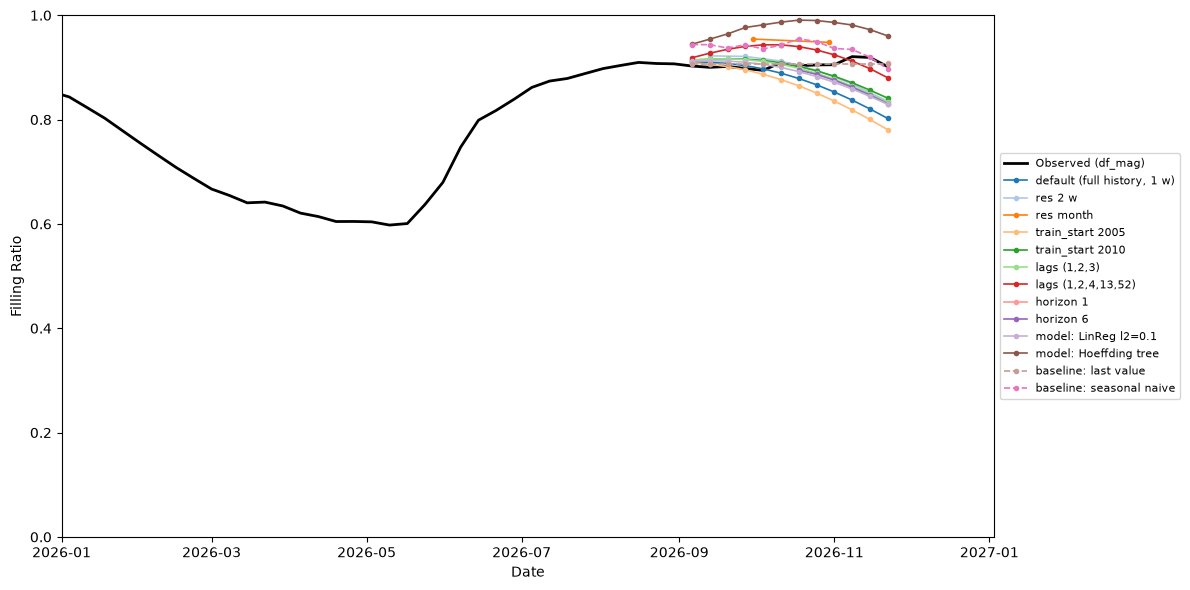

,Setting,Seconds,MAE mean,MAE median,MAE worst,Pts/origin
0,"default (full history, 1 w)",0.031,0.069,0.052,0.213,12.0
1,res 2 w,0.015,0.069,0.057,0.186,6.0
2,res month,0.010,0.060,0.049,0.164,2.0
3,train_start 2005,0.018,0.072,0.056,0.216,12.0
4,train_start 2010,0.013,0.082,0.069,0.282,12.0
5,"lags (1,2,3)",0.025,0.069,0.056,0.221,12.0
6,"lags (1,2,4,13,52)",0.028,0.068,0.050,0.208,12.0
7,horizon 1,0.026,0.015,0.011,0.071,1.0
8,horizon 6,0.027,0.042,0.033,0.175,6.0
9,model: LinReg l2=0.1,0.030,0.071,0.057,0.180,12.0


In [ ]:
# This code is in large part AI-derived. The comments are not written
# by the project author, though the code as still been studied in detail.
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from river import linear_model, preprocessing, tree


# --- Block 1: choose a region and extract its series ---------------------------
regions = df_mag[["Area Type", "Area Number"]].drop_duplicates()
print(regions)
area_type, area_number = regions.iloc[1]   # overwrite manually to test another region

region = df_mag[(df_mag["Area Type"] == area_type) & (df_mag["Area Number"] == area_number)]
region = region.dropna(subset=["Filling Ratio"]).sort_values("Date").reset_index(drop=True)

# --- Block 2: rolling origins --------------------------------------------------
# An origin o means: train on region.iloc[:o], forecast the weeks after it.
# The latest origin is `horizon` weeks before the latest observation, so its
# forecast ends on the latest observation. Origins then step back every
# `spacing` weeks until `years` years before the latest origin.
years, spacing = 10, 4

def make_origins(horizon):
    latest = len(region) - horizon
    earliest = latest - 52 * years
    return list(range(latest, earliest - 1, -spacing))[::-1]

# --- Block 3: baselines (reference points for judging the MAE values) ----------
def baseline_last_value(train, area_type, area_number, horizon):
    last_row = train.iloc[-1]
    dates = [last_row["Date"] + pd.Timedelta(weeks=h) for h in range(1, horizon + 1)]
    return pd.DataFrame({"Date": dates, "Forecast": last_row["Filling Ratio"]})

def baseline_seasonal_naive(train, area_type, area_number, horizon):
    # value observed 52 weeks before each target date (needs horizon <= 52)
    dates = [train["Date"].iloc[-1] + pd.Timedelta(weeks=h) for h in range(1, horizon + 1)]
    values = [train["Filling Ratio"].iloc[-52 + h - 1] for h in range(1, horizon + 1)]
    return pd.DataFrame({"Date": dates, "Forecast": values})

# --- Block 4: evaluation helper (averages the error over all origins) ----------
def evaluate(fn, horizon, **kwargs):
    maes, seconds, points = [], [], []
    for o in make_origins(horizon):
        train = region.iloc[:o]
        actual = region.iloc[o:o + horizon][["Date", "Filling Ratio"]]

        start = time.perf_counter()
        fc = fn(train, area_type, area_number, horizon=horizon, **kwargs)
        seconds.append(time.perf_counter() - start)

        # match each forecast date to the nearest observed week (max 4 days apart)
        matched = pd.merge_asof(fc, actual, on="Date", direction="nearest",
                                tolerance=pd.Timedelta(days=4)).dropna()
        maes.append((matched["Forecast"] - matched["Filling Ratio"]).abs().mean())
        points.append(len(matched))
    return {
        "Seconds": round(np.mean(seconds), 3),
        "MAE mean": round(np.mean(maes), 3),
        "MAE median": round(np.median(maes), 3),
        "MAE worst": round(np.max(maes), 3),
        "Pts/origin": round(np.mean(points), 1),
    }

# --- Block 5: settings to compare (one factor changed at a time from default) --
# Developer block: edit `base` and `experiments`, then rerun the cell. Every key
# in a settings dict is passed straight to forecast_filling() (train_start,
# train_end, horizon, resolution, lags, model). train_start/train_end are fixed
# dates, so train_start must lie well before the earliest origin printed below.
base = {"horizon": 12}
experiments = {
    "default (full history, 1 w)": {},
    "res 2 w":               {"resolution": 2},
    "res month":             {"resolution": "M"},
    "train_start 2005":      {"train_start": "2005-01-01"},
    "train_start 2010":      {"train_start": "2010-01-01"},
    "lags (1,2,3)":          {"lags": (1, 2, 3)},
    "lags (1,2,4,13,52)":    {"lags": (1, 2, 4, 13, 52)},
    "horizon 1":             {"horizon": 1},
    "horizon 6":             {"horizon": 6},
    "model: LinReg l2=0.1":  {"model": preprocessing.StandardScaler() | linear_model.LinearRegression(l2=0.1)},
    "model: Hoeffding tree": {"model": tree.HoeffdingTreeRegressor()},
}
runs = {name: (forecast_filling, kwargs) for name, kwargs in experiments.items()}
runs["baseline: last value"] = (baseline_last_value, {})
runs["baseline: seasonal naive"] = (baseline_seasonal_naive, {})

origins = make_origins(base["horizon"])
print(f"{len(origins)} origins (horizon {base['horizon']}) from "
      f"{region['Date'].iloc[origins[0] - 1].date()} to {region['Date'].iloc[origins[-1] - 1].date()}")

# --- Block 6: run, collect results, plot the most recent forecast --------------
# The table is scored over all rolling origins. The figure shows, for each setting,
# the forecast from the latest possible origin (the last `horizon` weeks held out).
plot_start = pd.Timestamp("2026-01-01", tz=region["Date"].dt.tz)
colors = plt.cm.tab20.colors

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(region["Date"], region["Filling Ratio"], color="black", lw=2, label="Observed (df_mag)")

rows = []
for i, (name, (fn, kwargs)) in enumerate(runs.items()):
    params = {**base, **kwargs}
    rows.append({"Setting": name, **evaluate(fn, **params)})

    fc = fn(region.iloc[:-params["horizon"]], area_type, area_number, **params)
    ax.plot(fc["Date"], fc["Forecast"], marker="o", ms=3, lw=1.2, color=colors[i],
            ls="--" if name.startswith("baseline") else "-", label=name)

last_date = region["Date"].iloc[-1]
ax.set_xlim(plot_start, last_date + pd.Timedelta(weeks=6))
ax.set_ylim(0, 1)   # keeps diverging runs from compressing the rest of the plot
ax.set_xlabel("Date")
ax.set_ylabel("Filling Ratio")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
fig.tight_layout()
plt.show()

results = pd.DataFrame(rows)
results


### 2.4 Test Report

The testing was done partly using the test code cell above and partly through the Streamlit-ported forecast, wherein training range, resolution, and horizon parameters can be varied and tested against each other on-the-go with clearer, faster visuals. The test code cell above was useful for identifying runtimes and which model options to give in Streamlit based on MAE mean, but was deemed too weighty to be more practical than Streamlit testing for other parameters.

Essentially, the test cell was used to establish which models and parameter combinations gave the most accurate forecasts. Then later Streamlit was used to explore how model and variable combinations affected the real forecast.

Tests were ran across the various area types and numbers using the test cell above by replacing the regions.iloc[n], such that options for user inputs in Streamlit could be decided.

Results across tests have been qualitatively assessed and compiled into the findings below by the author. Statistics can be ran on multiple tests to establish quantitative backing, this has been deemed outside the scope of the course.

Findings:
* Runtime does not discriminate between resolutions.
* Hoeffding tree and StandardScaler | Linear (default) models chosen as options for the user. Both outperformed naive baselines.
* Monthly resolution performed slightly (1%) better overall, with overall lower median and worst-case MAE. Not enough to be considered significant. 1 week, 2 week, and monthly resolutions given as options for the user.
* No surprise longer horizon = higher MAE mean, i.e. forecasts become less accurate the further ahead in time they are to forecast for. Horizon 1-12 week range given as options for the user.
* Training on older years generally decreases forecast. Less precipitation in the 90's and early 2000's perhaps?
* Restricting training to more recent years generally worsened accuracy.

## 3. Page Layout, Correlation Report

### 3.1 Streamlit Page Layout Sketch

![Streamlit page layout sketch](images/page_layout_demo.png)

### 3.2 Correlation Report

Precipitation correlates with Filling Ratio for given seasons, but does not correlate for others. This is generally true across EL areas. This is as expected: In the spring and autumn, there is generally more rain, which leads to generally higher Filling Ratio. In the winter, there is generally more snow, which does not correlate with higher Filling Ratio nearly as strongly as rain does. In the winter, there is also generally higher demand for electricity due to, among other things, heating.

When the Sliding Window is set to >12 weeks (approximately one season, depending on EL area number), the correlation falls. When the Sliding Window is set to 52 weeks, correlation is generally close to zero, and not stronger than 0.5. This follows from the seasonal correlation mentioned before: Fall especially correlates, winter does not, and over the whole year seasons more or less cancel each other. Again, depending on EL area.